# Base 14 – Empresa de Mineração
## Notebook 2 – Análise de séries temporais

**Projeto Integrador – Engenharia de Computação – FHO – 6º semestre**

Continuação do notebook 1 (`01_Dados_Limpeza_Estatistica_Agrupamento_Base14.ipynb`), que explica os dados, a limpeza, a estatística e o agrupamento. Aqui os mesmos dados são vistos **ao longo do tempo**. O roteiro segue `Analise_Series_Temporais_Engenharia_Computacao.ipynb` do professor, citado como **[ST nº]**.

**Perguntas deste notebook**

| # | Pergunta | Técnica (seção do material) |
|---|----------|------------------------------|
| P15 | A produtividade diária tem tendência ou sazonalidade? | Janelas móveis, calendário, STL [ST 11–14] |
| P16 | A série depende do passado? É estacionária? | ACF/PACF, Ljung-Box, ADF, KPSS [ST 15–16] |
| P17 | Dá para prever a produtividade da próxima semana melhor que uma referência simples? | Referências, Holt-Winters, SARIMA, Random Forest com defasagens [ST 18–28] |
| P18 | Quando um caminhão precisa de manutenção? (analogia da bolsa: segurar ou vender) | Sinal por janela móvel e limite de controle |

**Seções do material que ficaram de fora:** ST1–ST3 (ambiente e Python básico), ST5 (base didática; usamos a nossa), ST7 (já resolvido na limpeza do notebook 1) e ST34–ST35 (sinal de sensor e aliasing, que não se aplicam a registros de operação).

### Sumário
1. Problema e preparação da série
2. Análise da série (tendência, sazonalidade, decomposição, autocorrelação, estacionariedade)
3. Previsão (referências, modelos, validação e teste)
4. Sinal de manutenção por caminhão
5. Conclusões

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
# FutureWarning avisa só mudanças futuras de API (ex.: adfuller); não afeta resultados
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', '{:,.3f}'.format)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)

# No Colab: enviar o arquivo para a sessão (ou montar o Drive) e ajustar o caminho
CAMINHO = 'base_14_empresa_mineracao_limpa.csv'
df = pd.read_csv(CAMINHO, sep=';', encoding='utf-8-sig', parse_dates=['data_operacao'])
df = df.sort_values('data_operacao').reset_index(drop=True)
# Auditoria do tempo [ST 6]: a data precisa ser data (não texto) e estar em ordem
print('Tipo da coluna de data:', df['data_operacao'].dtype)
print('Datas em ordem:', df['data_operacao'].is_monotonic_increasing, '| linhas:', len(df))

Tipo da coluna de data: datetime64[us]
Datas em ordem: True | linhas: 9850


## 1. Problema e preparação da série

### 1.1 Formular o problema [ST 4, ST 36]

- **Variável:** produtividade média diária das operações (t/h). Usar a média, não a soma: a soma de toneladas depende de quantas operações houve no dia, e isso varia (6 a 28 por dia).
- **Frequência:** diária. Com só 20 meses, sazonalidade anual não é estimável (exige ao menos 2 ciclos completos). Período sazonal candidato: 7 dias (semana).
- **Horizonte e protocolo:** previsão dos **próximos 7 dias** emitida no início de cada semana, para planejamento semanal da lavra. Depois de cada semana, os dados reais entram no histórico [ST 18].
- **Divisão cronológica (nunca aleatória) [ST 10]:** treino até 28/02/2026, validação de 01/03/2026 a 31/05/2026, teste de 01/06/2026 a 31/08/2026.

### 1.2 Construir o calendário e medir lacunas [ST 8, ST 9]

In [2]:
diario = (df.set_index('data_operacao').resample('D')
            .agg(produtividade=('produtividade_t_h', 'mean'), n_operacoes=('registro_id', 'count'),
                 massa_produto_t=('massa_produto_t', 'sum'), falhas=('qtd_falhas_equipamento', 'sum'),
                 custo_rs=('custo_operacional_rs', 'sum')))
diario['custo_por_t'] = diario['custo_rs'] / diario['massa_produto_t']
print('Dias:', len(diario), '| dias sem operação:', (diario['n_operacoes'] == 0).sum())
y = diario['produtividade'].asfreq('D')
FIM_TREINO, FIM_VALID = '2026-02-28', '2026-05-31'
treino = y[:FIM_TREINO]
valid = y[pd.Timestamp(FIM_TREINO) + pd.Timedelta(days=1):FIM_VALID]
teste = y[pd.Timestamp(FIM_VALID) + pd.Timedelta(days=1):]
print(f'treino {len(treino)} dias | validação {len(valid)} | teste {len(teste)}')
diario.describe().T

Dias: 608 | dias sem operação: 0
treino 424 dias | validação 92 | teste 92


,count,mean,std,min,25%,50%,75%,max
produtividade,608.000,175.808,7.486,151.025,170.987,175.815,180.788,202.875
n_operacoes,608.000,16.201,4.069,6.000,13.000,16.000,19.000,28.000
massa_produto_t,608.000,"25,654.686","6,638.537","9,137.500","20,572.660","25,443.915","29,920.743","45,709.310"
falhas,608.000,15.688,4.965,4.000,12.000,15.000,19.000,31.000
custo_rs,608.000,"426,226.652","116,020.794","139,883.200","342,745.997","417,598.625","503,948.220","792,190.960"
custo_por_t,608.000,16.695,2.240,10.755,15.227,16.446,17.998,26.124


## 2. Análise da série

### 2.1 Tendência e janelas móveis [ST 11, ST 12] – P15

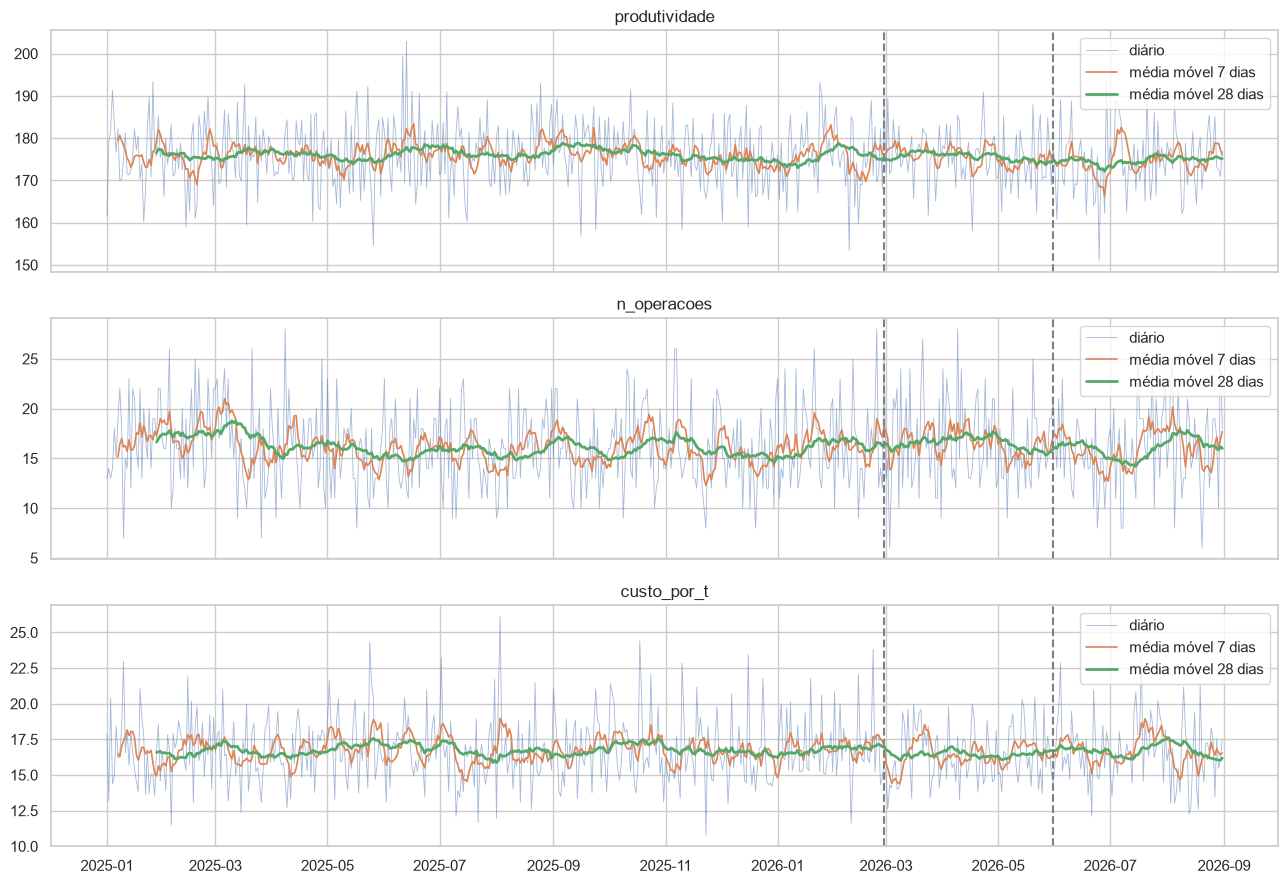

Média por trimestre (t/h):
data_operacao
2025Q1   176.290
2025Q2   175.950
2025Q3   176.500
2025Q4   175.390
2026Q1   176.450
2026Q2   174.860
2026Q3   175.430
Freq: Q-DEC


In [3]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, col in zip(axes, ['produtividade', 'n_operacoes', 'custo_por_t']):
    s = diario[col]
    ax.plot(s, lw=.6, alpha=.5, label='diário')
    ax.plot(s.rolling(7).mean(), lw=1.2, label='média móvel 7 dias')
    ax.plot(s.rolling(28).mean(), lw=2, label='média móvel 28 dias')
    ax.set_title(col); ax.legend(loc='upper right')
for ax in axes:
    ax.axvline(pd.Timestamp(FIM_TREINO), color='gray', ls='--'); ax.axvline(pd.Timestamp(FIM_VALID), color='gray', ls='--')
plt.tight_layout(); plt.show()
print('Média por trimestre (t/h):')
print(df.groupby(df['data_operacao'].dt.to_period('Q'))['produtividade_t_h'].mean().round(2).to_string())

### 2.2 Sazonalidade pelo calendário [ST 13] – P15

Exploração **somente no treino**, para não usar informação do futuro.

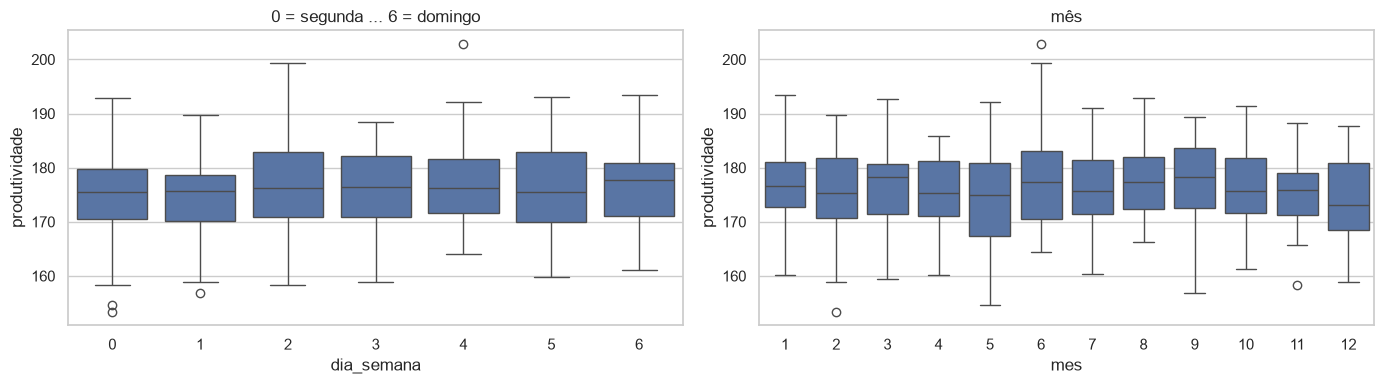

Kruskal-Wallis por dia da semana: KruskalResult(statistic=np.float64(3.033932770509864), pvalue=np.float64(0.8045760197790679))
Kruskal-Wallis por mês         : KruskalResult(statistic=np.float64(6.382203555189335), pvalue=np.float64(0.8466849903345639))


In [4]:
t = treino.to_frame('produtividade')
t['dia_semana'] = t.index.dayofweek
t['mes'] = t.index.month
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=t, x='dia_semana', y='produtividade', ax=axes[0]); axes[0].set_title('0 = segunda ... 6 = domingo')
sns.boxplot(data=t, x='mes', y='produtividade', ax=axes[1]); axes[1].set_title('mês')
plt.tight_layout(); plt.show()
print('Kruskal-Wallis por dia da semana:', stats.kruskal(*[g['produtividade'] for _, g in t.groupby('dia_semana')]))
print('Kruskal-Wallis por mês         :', stats.kruskal(*[g['produtividade'] for _, g in t.groupby('mes')]))

### 2.3 Decomposição STL [ST 14] – P15

STL separa a série em **tendência + sazonal + resíduo**. A força de cada componente vai de 0 (inexistente) a 1 (domina a série): $F = \max(0,\ 1 - \mathrm{Var}(R)/\mathrm{Var}(C+R))$.

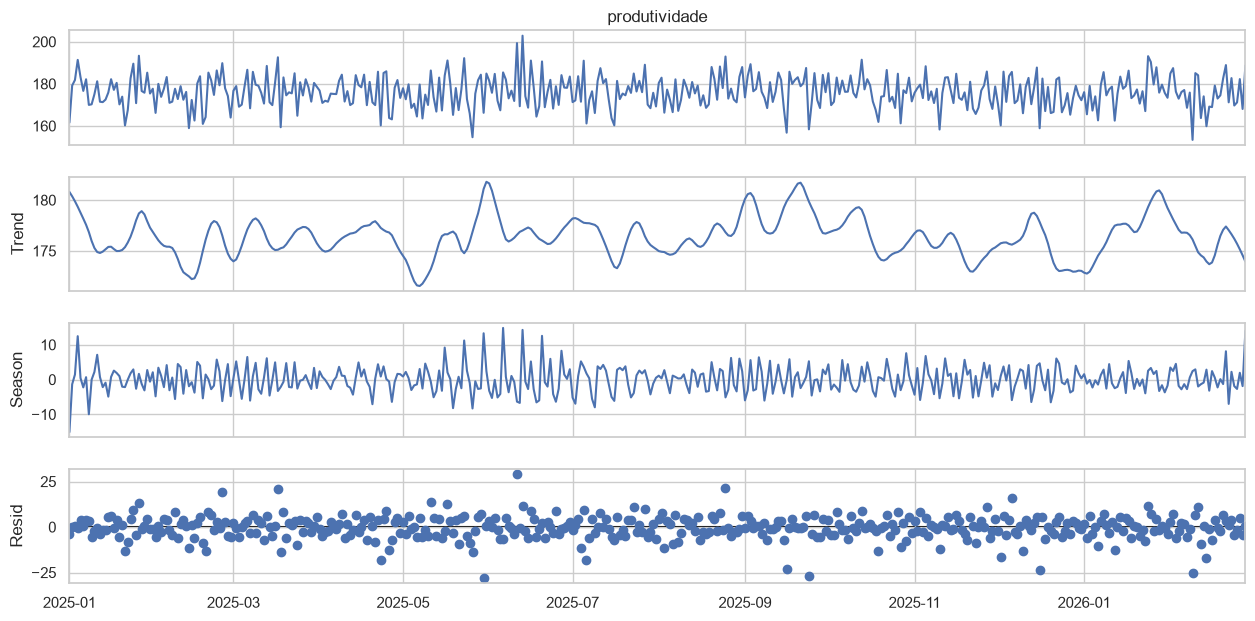

Força da tendência = 0.102 | força da sazonalidade semanal = 0.255


In [5]:
stl = STL(treino, period=7, robust=True).fit()
stl.plot(); plt.gcf().set_size_inches(13, 7); plt.show()
F_tend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
F_saz = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f'Força da tendência = {F_tend:.3f} | força da sazonalidade semanal = {F_saz:.3f}')

**Interpretação e decisão**

Pela visualização, as médias móveis de 28 dias ficam quase planas (175 a 177 t/h por trimestre). A quantidade de operações e o custo por tonelada também não têm tendência.

**Força da tendência = 0,10** e **força da sazonalidade semanal = 0,26**: os dois componentes são fracos. Kruskal-Wallis por dia da semana (p = 0,80) e por mês (p = 0,85) confirma que **não há sazonalidade real**. Os 0,26 vêm do STL tentando encaixar um padrão no ruído. Quase toda a variação diária está no resíduo.

### 2.4 Autocorrelação e estacionariedade [ST 15, ST 16] – P16

- **ACF/PACF:** barras fora da faixa azul indicam dependência com dias anteriores.
- **Ljung-Box:** H0 = série sem autocorrelação (ruído branco).
- **ADF:** H0 = série tem raiz unitária (não estacionária).
- **KPSS:** H0 = série estacionária. Os dois testes juntos dão uma conclusão mais segura.

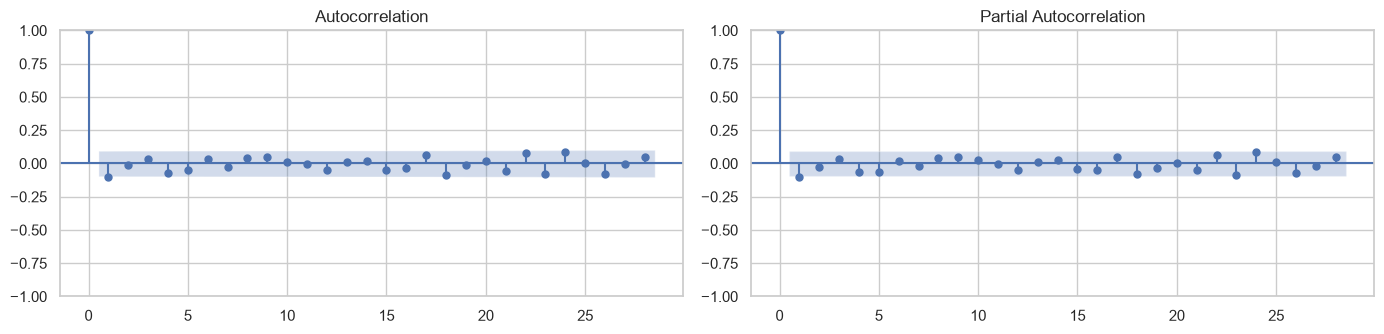

,lb_stat,lb_pvalue
7,8.741,0.272
14,12.107,0.598
28,33.270,0.226


ADF : estatística = -22.72  p = 0.0000
KPSS: estatística = 0.075  p >= 0.10


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(treino, lags=28, ax=axes[0]); plot_pacf(treino, lags=28, ax=axes[1], method='ywm')
plt.tight_layout(); plt.show()
display(acorr_ljungbox(treino, lags=[7, 14, 28]))
adf = adfuller(treino)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')  # KPSS avisa quando o p-valor passa do limite da tabela (> 0,1)
    kp = kpss(treino, regression='c', nlags='auto')
print(f'ADF : estatística = {adf[0]:.2f}  p = {adf[1]:.4f}')
print(f'KPSS: estatística = {kp[0]:.3f}  p >= {kp[1]:.2f}')

**Interpretação e decisão**

- **ACF/PACF:** nenhuma barra relevante fora da faixa de confiança.
- **Ljung-Box:** p = 0,27 (lag 7), 0,60 (lag 14) e 0,23 (lag 28). Não rejeita H0: **a série se comporta como ruído branco**. O valor de hoje não ajuda a prever o de amanhã.
- **ADF** rejeita raiz unitária (p < 0,001) e **KPSS** não rejeita estacionariedade (p ≥ 0,10). Os dois concordam: **série estacionária**, sem precisar de diferenciação (d = 0).

**Consequência para a previsão:** se não há tendência, sazonalidade nem autocorrelação, o melhor previsor teórico é a **média**. A seção 3.3 testa isso na prática.

### 2.5 Candidatos a anomalia no histórico [ST 17]

Dias com resíduo STL acima de 3 desvios robustos (MAD). São candidatos para investigar, não erros automáticos.

Dias candidatos: 12


,produtividade,n_operacoes,falhas
data_operacao,,,
2025-02-25,189.810,23,23
2025-03-17,192.602,12,11
2025-04-23,160.242,15,18
2025-05-30,166.225,16,13
2025-06-11,199.348,13,14
2025-07-06,161.155,13,8
2025-08-25,192.966,14,12
2025-09-16,156.787,10,11
2025-09-24,158.364,13,14


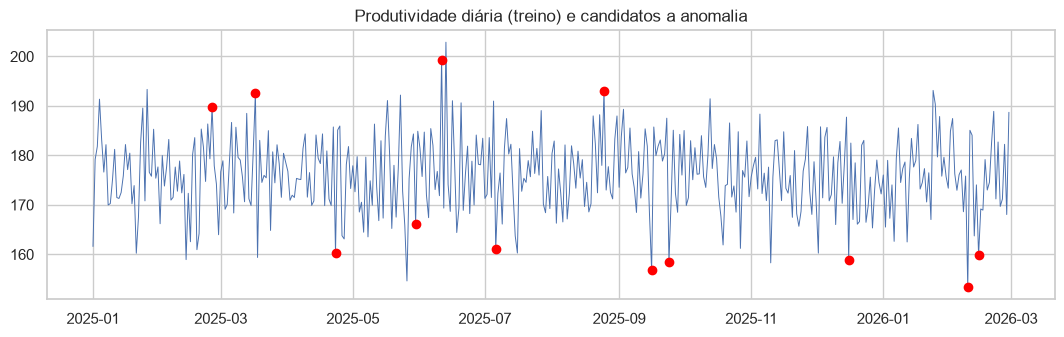

In [7]:
r = stl.resid
z_rob = (r - r.median()) / (1.4826 * stats.median_abs_deviation(r))
anom = treino[z_rob.abs() > 3]
print('Dias candidatos:', len(anom))
display(diario.loc[anom.index, ['produtividade', 'n_operacoes', 'falhas']])
plt.figure(figsize=(13, 3.5)); plt.plot(treino, lw=.7); plt.scatter(anom.index, anom, color='red', zorder=3)
plt.title('Produtividade diária (treino) e candidatos a anomalia'); plt.show()

**Interpretação e decisão**

Há 12 dias candidatos a anomalia no treino (2,8% dos dias). Alguns se explicam pelos dados do próprio dia. Em 25/02/2025, por exemplo, houve 23 operações (acima da média de 16) e produtividade alta. Em 14/02/2026 houve só 9 operações, então a média do dia ficou instável. **Decisão:** manter esses dias na série. São variações plausíveis de dias com poucas ou muitas operações, não erros de registro.

## 3. Previsão

O professor comentou que, a partir dos índices 14–15 do material, o conteúdo serve só para algumas situações. A análise acima mostra se vale a pena prever esta série e o que esperar dos modelos.

### 3.1 Protocolo, métricas e referências simples [ST 18, ST 19, ST 20] – P17

Funções adaptadas do material [ST 19]. MAE = erro típico em t/h. RMSE pesa mais erros grandes. Viés positivo = superestimação.

Referências simples antes de modelos complexos:
- **média histórica**: média de todo o histórico disponível;
- **persistência**: repete o último dia;
- **média móvel 7**: média da última semana;
- **sazonal ingênuo**: repete o mesmo dia da semana anterior.

In [8]:
H = 7  # horizonte: 1 semana

def metricas(real, previsto):
    real, previsto = real.align(previsto, join='inner')
    m = real.notna() & previsto.notna()
    r, p = real[m], previsto[m]
    return {'MAE_t_h': mean_absolute_error(r, p), 'RMSE_t_h': np.sqrt(mean_squared_error(r, p)),
            'Vies_t_h': float((p - r).mean()), 'N': len(r)}

def avaliar_blocos(historico, futuro, funcao, horizonte=H):
    historico = historico.copy()
    partes = []
    for inicio in range(0, len(futuro), horizonte):
        bloco = futuro.iloc[inicio:inicio + horizonte]
        valores = np.asarray(funcao(historico, bloco.index), dtype=float).reshape(-1)
        partes.append(pd.Series(valores, index=bloco.index))
        historico = pd.concat([historico, bloco]).asfreq('D')  # bloco real entra após a semana
    return pd.concat(partes)

def media_historica(h, idx): return np.repeat(h.mean(), len(idx))
def persistencia(h, idx):    return np.repeat(h.iloc[-1], len(idx))
def media_movel_7(h, idx):   return np.repeat(h.iloc[-7:].mean(), len(idx))
def sazonal_ingenuo(h, idx): return np.resize(h.iloc[-7:].values, len(idx))

### 3.2 Modelos: Holt-Winters, SARIMA e Random Forest com defasagens [ST 21, ST 23, ST 24, ST 25]

- **Holt-Winters** sem tendência (a seção 2.3 não mostrou tendência), com sazonalidade aditiva de 7 dias.
- **SARIMA(1,0,0)(1,0,0)₇** sobre a série centrada na média do histórico: d = 0 porque ADF/KPSS indicaram estacionariedade; ordens baixas porque ACF/PACF não mostraram dependência forte. Uma primeira tentativa com SARIMA(1,0,1)(1,0,1)₇ sem constante não convergiu (MAE de 44 t/h) e foi descartada.
- **Random Forest** transforma a série em problema supervisionado com defasagens de 1, 7 e 14 dias e o dia da semana. A previsão dos 7 dias é recursiva: o valor previsto vira defasagem do dia seguinte [ST 25].

In [9]:
def holt_winters(h, idx):
    m = ExponentialSmoothing(h, trend=None, seasonal='add', seasonal_periods=7).fit()
    return m.forecast(len(idx)).values

AVISOS_SARIMA = []
def sarima(h, idx):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        mu = h.mean()  # centralizar: sem isso o modelo sem constante não converge
        m = SARIMAX(h - mu, order=(1, 0, 0), seasonal_order=(1, 0, 0, 7)).fit(disp=False)
    AVISOS_SARIMA.extend(str(x.message)[:80] for x in w)
    return m.forecast(len(idx)).values + mu

LAGS = [1, 7, 14]
def rf_defasagens(h, idx):
    base = pd.DataFrame({'y': h})
    for l in LAGS:
        base[f'lag{l}'] = base['y'].shift(l)
    base['dia_semana'] = base.index.dayofweek
    base = base.dropna()
    modelo = RandomForestRegressor(300, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
    modelo.fit(base.drop(columns='y'), base['y'])
    hist, prev = h.copy(), []
    for t in idx:
        x = pd.DataFrame([{**{f'lag{l}': hist.iloc[-l] for l in LAGS}, 'dia_semana': t.dayofweek}])
        p = modelo.predict(x)[0]
        prev.append(p)
        hist = pd.concat([hist, pd.Series([p], index=[t])])
    return np.array(prev)

CANDIDATOS = {'média histórica': media_historica, 'persistência': persistencia,
              'média móvel 7': media_movel_7, 'sazonal ingênuo': sazonal_ingenuo,
              'Holt-Winters': holt_winters, 'SARIMA': sarima, 'Random Forest (lags)': rf_defasagens}

### 3.3 Comparar candidatos na validação e escolher antes do teste [ST 26, ST 27]

In [10]:
prev_valid = {nome: avaliar_blocos(treino, valid, f) for nome, f in CANDIDATOS.items()}
res_valid = pd.DataFrame({nome: metricas(valid, p) for nome, p in prev_valid.items()}).T.sort_values('MAE_t_h')
print('Avisos de convergência do SARIMA:', len(AVISOS_SARIMA))
res_valid

Avisos de convergência do SARIMA: 0


,MAE_t_h,RMSE_t_h,Vies_t_h,N
Holt-Winters,4.824,6.201,0.533,92.000
média histórica,4.842,6.250,0.532,92.000
SARIMA,4.865,6.276,0.567,92.000
Random Forest (lags),5.029,6.449,0.450,92.000
média móvel 7,5.414,6.813,0.023,92.000
persistência,6.730,8.489,-0.750,92.000
sazonal ingênuo,6.965,8.943,0.133,92.000


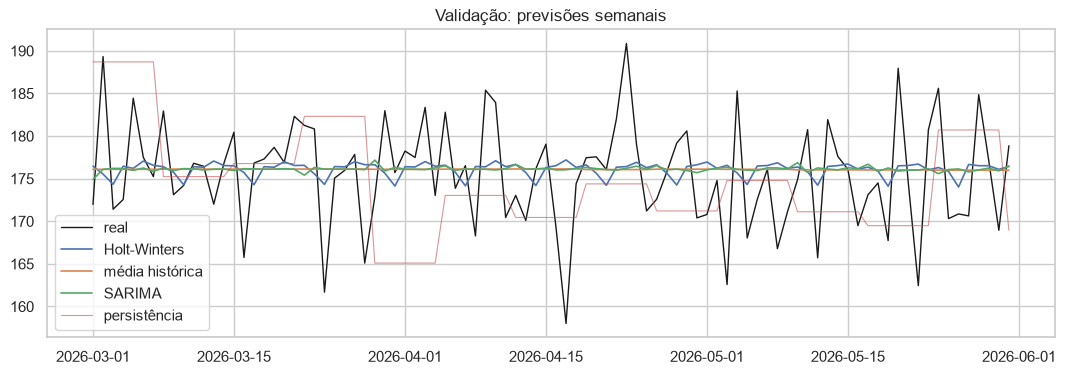

Melhor MAE: Holt-Winters (4.824)
Modelo escolhido na validação: média histórica


In [11]:
plt.figure(figsize=(13, 4))
plt.plot(valid, color='k', lw=1, label='real')
for nome in res_valid.index[:3]:
    plt.plot(prev_valid[nome], lw=1.2, label=nome)
plt.plot(prev_valid['persistência'], lw=.8, alpha=.6, label='persistência')
plt.title('Validação: previsões semanais'); plt.legend(); plt.show()
# Regra definida antes de ver o teste: o modelo mais simples (ordem do dicionário CANDIDATOS)
# com MAE até 2% acima do melhor. Complexidade extra precisa se pagar [ST 36].
melhor = res_valid['MAE_t_h'].min()
ESCOLHIDO = next(n for n in CANDIDATOS if res_valid.loc[n, 'MAE_t_h'] <= melhor * 1.02)
print(f'Melhor MAE: {res_valid.index[0]} ({melhor:.3f})')
print('Modelo escolhido na validação:', ESCOLHIDO)

**Interpretação e decisão**

Ranking na validação (MAE em t/h): Holt-Winters 4,82, **média histórica 4,84**, SARIMA 4,87, Random Forest 5,03, média móvel 7 dias 5,41, persistência 6,73 e sazonal ingênuo 6,97.

Holt-Winters, média histórica e SARIMA empatam: a diferença é de 0,04 t/h, menos de 1%. Os modelos que copiam o passado recente (persistência e sazonal ingênuo) são os piores, porque copiam ruído. **Pela regra definida antes do teste, o modelo escolhido é a média histórica.** Os modelos complexos não compensam a complexidade, como a seção 2.4 já indicava.

O SARIMA terminou sem avisos de convergência depois de centralizar a série. A versão inicial sem constante errava 44 t/h.

### 3.4 Avaliar uma única vez no teste reservado [ST 28, ST 29, ST 30]

In [12]:
hist_teste = pd.concat([treino, valid]).asfreq('D')
prev_teste = {nome: avaliar_blocos(hist_teste, teste, CANDIDATOS[nome])
              for nome in dict.fromkeys([ESCOLHIDO, 'Holt-Winters', 'SARIMA', 'Random Forest (lags)', 'sazonal ingênuo', 'persistência'])}
res_teste = pd.DataFrame({n: metricas(teste, p) for n, p in prev_teste.items()}).T
display(res_teste)

erro_teste = teste - prev_teste[ESCOLHIDO]
horizonte = pd.Series(np.tile(np.arange(1, H + 1), len(teste) // H + 1)[:len(teste)], index=teste.index)
print('MAE por dia do horizonte (1 = primeiro dia da semana prevista):')
print(erro_teste.abs().groupby(horizonte).mean().round(2).to_string())
print('Ljung-Box dos erros (lag 7):', acorr_ljungbox(erro_teste, lags=[7]).round(3).to_dict('records'))

,MAE_t_h,RMSE_t_h,Vies_t_h,N
média histórica,5.885,7.643,1.150,92.000
Holt-Winters,5.952,7.751,1.146,92.000
SARIMA,5.905,7.670,1.167,92.000
Random Forest (lags),5.995,8.095,1.110,92.000
sazonal ingênuo,8.196,10.578,-0.120,92.000
persistência,8.994,11.216,-0.076,92.000


MAE por dia do horizonte (1 = primeiro dia da semana prevista):
1   7.750
2   5.500
3   4.570
4   7.840
5   4.230
6   5.140
7   6.020
Ljung-Box dos erros (lag 7): [{'lb_stat': 3.65, 'lb_pvalue': 0.819}]


### 3.5 Intervalo de previsão e previsão realmente futura [ST 31, ST 32]

Intervalo empírico de 90%: quantis 5% e 95% dos erros na validação, somados à previsão. A cobertura real é medida no teste.

In [13]:
erro_valid = valid - prev_valid[ESCOLHIDO]
q05, q95 = erro_valid.quantile(.05), erro_valid.quantile(.95)
dentro = ((teste >= prev_teste[ESCOLHIDO] + q05) & (teste <= prev_teste[ESCOLHIDO] + q95)).mean()
print(f'Intervalo: previsão {q05:+.1f} / {q95:+.1f} t/h | cobertura no teste = {dentro*100:.1f}% (nominal 90%)')

hist_total = y.copy()
futuro_idx = pd.date_range(hist_total.index[-1] + pd.Timedelta(days=1), periods=H, freq='D')
futuro = pd.DataFrame({'previsao_t_h': CANDIDATOS[ESCOLHIDO](hist_total, futuro_idx)}, index=futuro_idx)
futuro['limite_inf'] = futuro['previsao_t_h'] + q05
futuro['limite_sup'] = futuro['previsao_t_h'] + q95
futuro

Intervalo: previsão -10.7 / +9.2 t/h | cobertura no teste = 76.1% (nominal 90%)


,previsao_t_h,limite_inf,limite_sup
2026-09-01,175.808,165.141,185.036
2026-09-02,175.808,165.141,185.036
2026-09-03,175.808,165.141,185.036
2026-09-04,175.808,165.141,185.036
2026-09-05,175.808,165.141,185.036
2026-09-06,175.808,165.141,185.036
2026-09-07,175.808,165.141,185.036


**Interpretação e decisão**

No teste (jun–ago/2026), a **média histórica ficou em primeiro lugar** (MAE 5,89 t/h), à frente de SARIMA (5,91), Holt-Winters (5,95) e Random Forest (6,00). A escolha feita na validação se confirmou.

- **Erro maior que na validação** (4,8 para 5,9) em todos os modelos: o trimestre de teste variou mais. O viés de +1,15 t/h mostra que a produtividade do teste ficou cerca de 1 t/h abaixo da média histórica.
- **Erro por horizonte:** não cresce com o dia da semana prevista. Faz sentido, porque a previsão é a mesma para os 7 dias.
- **Erros sem autocorrelação** (Ljung-Box p = 0,82): não sobrou padrão que outro modelo pudesse aproveitar.
- **Intervalo de 90%:** cobriu só 76% no teste, porque foi calibrado em um período mais calmo. Para uso real, alargar o intervalo ou recalibrar com mais dados.

**Previsão para 01–07/09/2026:** 175,8 t/h por dia, com faixa de 165 a 185 t/h.

## 4. P18 – Sinal de manutenção por caminhão (analogia da bolsa)

Na bolsa, a decisão é segurar ou vender a ação. Na mina, a decisão é **manter o caminhão rodando ou parar para manutenção**.

**Regra:** para cada caminhão, calcular a média semanal de falhas por operação, suavizada por janela móvel de 4 semanas. O limite de alerta é média + 2 desvios dessa janela **no período de treino**. Semana acima do limite = sinal de "parar para manutenção".

Semanas em alerta após o treino, por caminhão:
equipamento_transporte
CAM-107    1
CAM-101    0
CAM-103    0
CAM-102    0
CAM-104    0
CAM-105    0
CAM-106    0
CAM-108    0


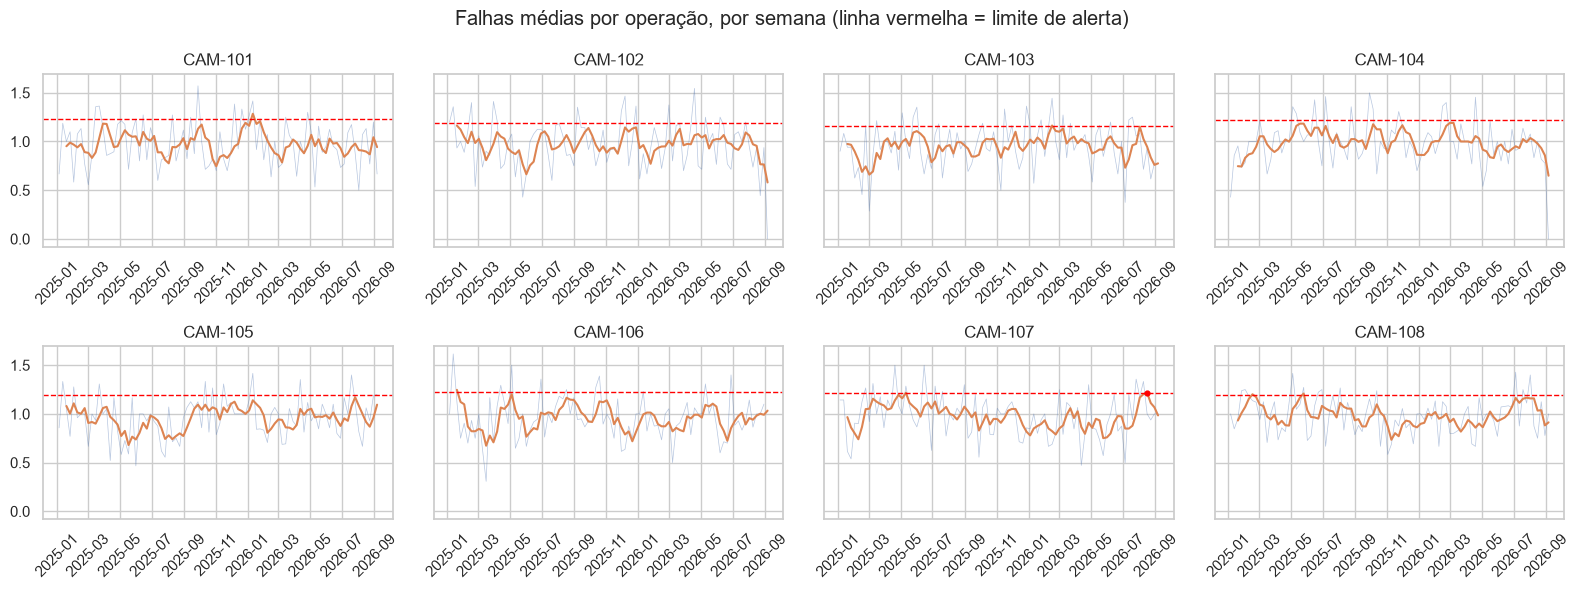

In [14]:
sem = (df.groupby([pd.Grouper(key='data_operacao', freq='W'), 'equipamento_transporte'])['qtd_falhas_equipamento']
         .mean().unstack())
suave = sem.rolling(4, min_periods=3).mean()
base_tr = suave[:FIM_TREINO]
limite = base_tr.mean() + 2 * base_tr.std()
alertas = suave[pd.Timestamp(FIM_TREINO):] > limite
print('Semanas em alerta após o treino, por caminhão:')
print(alertas.sum().sort_values(ascending=False).to_string())

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
for ax, cam in zip(axes.flat, sem.columns):
    ax.plot(sem[cam], lw=.5, alpha=.4); ax.plot(suave[cam], lw=1.5)
    ax.axhline(limite[cam], color='red', ls='--', lw=1)
    a = suave[cam][pd.Timestamp(FIM_TREINO):][alertas[cam]]
    ax.scatter(a.index, a, color='red', s=12, zorder=3)
    ax.set_title(cam); ax.tick_params(axis='x', rotation=45)
plt.suptitle('Falhas médias por operação, por semana (linha vermelha = limite de alerta)')
plt.tight_layout(); plt.show()

**Interpretação e decisão**

Com o limite de média + 2 desvios calibrado no treino, só **1 semana de alerta** aconteceu depois do treino, no CAM-107. Os 8 caminhões seguem o mesmo padrão de falhas ao longo do tempo, como o agrupamento hierárquico do notebook 1 (seção 4.5) já mostrava.

**Analogia da bolsa:** a regra funciona como uma ordem automática. Enquanto a média móvel de falhas fica abaixo do limite, "segura" (mantém o caminhão rodando). Quando cruza o limite, "vende" (para e faz manutenção preventiva). Nesta base, a regra quase não dispara, porque a falha depende do turno e não do desgaste do caminhão. A ferramenta está pronta para dados reais, onde o desgaste deve aparecer.

## 5. Conclusões do notebook 2


### 5.1 Resultados

| # | Pergunta | Resposta | Evidência |
|---|----------|----------|-----------|
| P15 | A produtividade tem tendência ou sazonalidade? | **Não.** As médias trimestrais ficam entre 175 e 177 t/h, e não há padrão por dia da semana nem por mês | STL: força da tendência 0,10 e da sazonalidade 0,26; Kruskal p = 0,80 e 0,85 |
| P16 | A série depende do passado? É estacionária? | **Não depende** (ruído branco) e **é estacionária** | Ljung-Box p > 0,2; ADF p < 0,001; KPSS p ≥ 0,10 |
| P17 | Dá para prever a semana melhor que a média? | **Não.** A média histórica venceu na validação e no teste (MAE de 5,9 t/h). Holt-Winters, SARIMA e Random Forest empataram ou perderam | Validação e teste cronológicos, previsão semanal |
| P18 | Quando parar um caminhão? | A regra de alerta está pronta, mas disparou só 1 vez (CAM-107) | Média móvel de 4 semanas e limite de controle |

### 5.2 O que isso significa

- A produtividade diária varia em torno de **176 t/h, com desvio de cerca de 7 t/h**. Essa variação é aleatória: não existe tendência, ciclo semanal ou memória que um modelo possa aproveitar.
- Por isso, **para planejar a semana, a melhor estimativa é a média histórica** (175,8 t/h, com faixa de 165 a 185 t/h). Modelos complexos não melhoram a previsão e custam mais para manter.
- A variação que importa está **dentro do dia**, entre operações: o turno da noite e as falhas de equipamento (notebook 1). As melhorias devem focar nesses fatores, não em prever a série.
- O alerta de manutenção funciona como na analogia da bolsa: segura enquanto a média móvel de falhas está abaixo do limite e "vende" (para o caminhão) quando passa. Nesta base quase não dispara, porque a falha depende do turno e não do desgaste do caminhão.

### 5.3 Limitações

- 20 meses não permitem estudar sazonalidade anual (chuva/seca). Para isso são necessários pelo menos 24 meses.
- O intervalo de previsão de 90% cobriu só 76% no teste. O período de teste variou mais que o de validação.
- Não dá para fazer série por operador: cada um tem cerca de 6 operações em 20 meses.
- A base parece simulada (série sem padrão, caminhões idênticos). Os métodos estão prontos para dados reais, mas os números valem só para esta base.

### 5.4 Próximos passos

- Com mais meses de dados, refazer a decomposição com período anual.
- Testar outras séries: custo por tonelada, falhas por semana e produtividade separada por turno.
- Na etapa de machine learning, a Random Forest com defasagens (seção 3.2) é o ponto de partida para modelos supervisionados com séries.